# 01 – Build the cube

Let's first download the data. We'll use NDMI and NDVI indices from Sentinel-2, weather variables from ERA5-Land, the Copernicus DEM and WorldCover. Then bring everything onto the 20m NDMI grid, compute the derived variables (anomalies, validity mask, gap-filled anomalies, month encoding, SPI, irrigated mask) and save the whole cube as a zarr file.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import getpass

%load_ext autoreload
%autoreload 2

from src.paths import PROCESSED
from src.sentinel2 import get_index
from src.era5 import get_era5
from src.static_layers import get_dem, get_worldcover
from src.grid import regrid, fill_sea, era5_to_grid, dem_to_grid, worldcover_to_grid
from src.indices import compute_anomaly, spi

c:\Users\DavidCirauqui\anaconda3\envs\drought\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sentinel Hub credentials: run the commented cell once to save the `cdse` profile, then only load it.

In [2]:
# config = SHConfig()
# config.sh_client_id = getpass.getpass("Enter your SentinelHub client id")
# config.sh_client_secret = getpass.getpass("Enter your SentinelHub client secret")
# config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
# config.sh_base_url = "https://sh.dataspace.copernicus.eu"
# config.save("cdse")

In [2]:
from sentinelhub import SHConfig
config = SHConfig("cdse")

In [3]:
# study area, period and variables
coords = [2.97, 41.92, 3.19, 42.10]   # Baix Empordà
resolution = 20
months = [[d.year, d.month] for d in pd.date_range("2017-04", "2025-12", freq="MS")]

era5_variables = [
    "total_precipitation",
    "2m_temperature",
    "potential_evaporation",
    "total_evaporation",
    "volumetric_soil_water_layer_1",
    "volumetric_soil_water_layer_2",
]

get all the data (each at its native resolution)

In [4]:
ndmi = get_index(coords, resolution, months, config, index = "ndmi")   # 20 m, defines the grid
ndvi = get_index(coords, resolution, months, config, index = "ndvi") 
era5 = get_era5(coords, months, era5_variables)            # ~9 km
dem = get_dem(coords)                                      # 30 m
wc = get_worldcover(coords)                                # 10 m

regrid all the data so that everything uses the NDMI's resolution

In [5]:
cube = xr.merge([
    ndmi,
    ndvi,
    era5_to_grid(era5, ndmi),
    dem_to_grid(dem, ndmi),
    worldcover_to_grid(wc, ndmi),
], join = "exact")
cube

C:\Users\DavidCirauqui\AppData\Local\Temp\ipykernel_27456\1093744552.py:1: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  cube = xr.merge([


<xarray.Dataset> Size: 3GB
Dimensions:                (time: 105, lat: 1000, lon: 910)
Coordinates:
  * time                   (time) datetime64[us] 840B 2017-04-01 ... 2025-12-01
  * lat                    (lat) float64 8kB 42.1 42.1 42.1 ... 41.92 41.92
  * lon                    (lon) float64 7kB 2.97 2.97 2.971 ... 3.189 3.19 3.19
Data variables: (12/26)
    ndmi_median            (time, lat, lon) float32 382MB 0.1721 ... -0.03355
    clear_count            (time, lat, lon) float32 382MB 6.0 6.0 ... 3.0 3.0
    ndvi_median            (time, lat, lon) float32 382MB 0.7481 ... 0.3222
    tp                     (time, lat, lon) float32 382MB 0.001044 ... 0.007493
    t2m                    (time, lat, lon) float32 382MB 287.3 287.3 ... 284.8
    pev                    (time, lat, lon) float32 382MB -0.006147 ... -0.00...
    ...                     ...
    lc_bare_sparse         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_snow_ice            (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_water               (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_herbaceous_wetland  (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_mangroves           (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_moss_lichen         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0

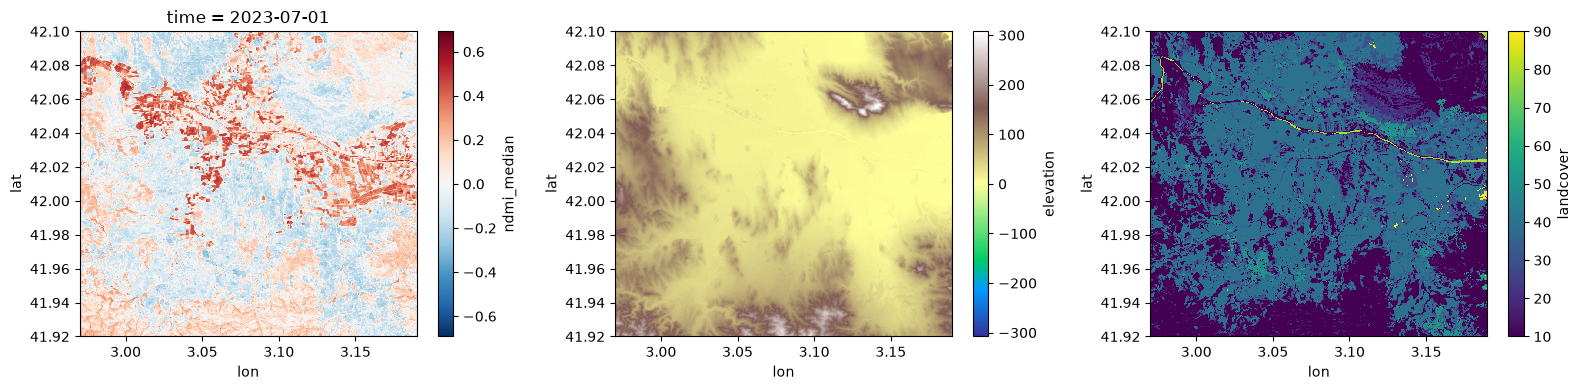

In [6]:
# quick check of the cube
fig, axes = plt.subplots(1, 3, figsize = (16, 4))
cube.ndmi_median.sel(time = "2023-07-01").plot(ax = axes[0])
cube.elevation.plot(ax = axes[1], cmap = "terrain")
cube.landcover.plot(ax = axes[2])
plt.tight_layout()

## Derived variables

We can engineer some derived variables that will be usefull when training a model to learn about the drought

Compute NDMI and NDVI. We only have 5 years in the training set: this will be enough for the mean, but stdv will be unstable if computed with that few points. Assume all months will have same spread (we loose some realism but gain better statistics): to this end, deseasonalise and then compute stdv

In [7]:
cube["ndmi_anomaly"] = compute_anomaly(cube.ndmi_median, train_years = slice("2017", "2021"))
cube["ndvi_anomaly"] = compute_anomaly(cube.ndvi_median, train_years = slice("2017", "2021"))

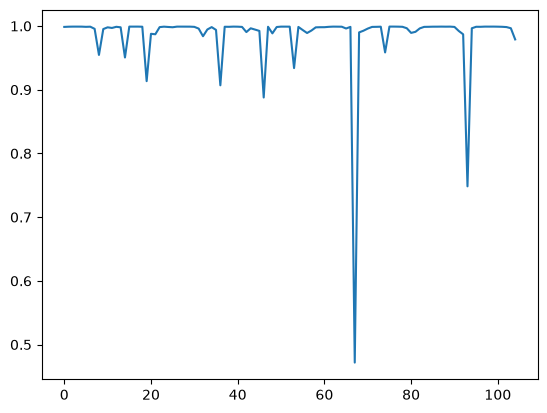

In [8]:
# let's check non-valid NDMI anomaly values
cube["valid_mask"] = cube.ndmi_anomaly.notnull().astype("uint8")


valid_ratio = cube.valid_mask.mean(["lat", "lon"])
plt.plot(valid_ratio)

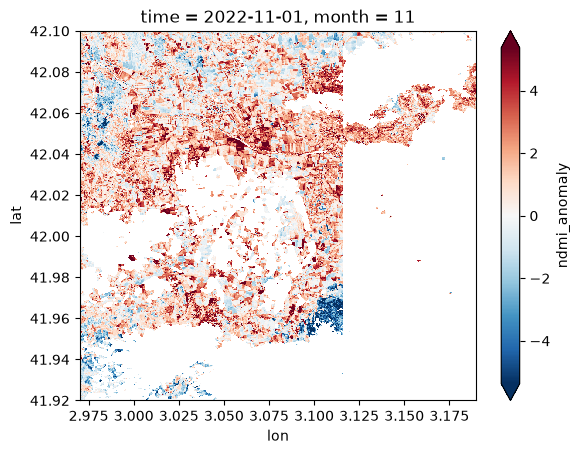

In [9]:
# we are missing data
idx = np.argmin(valid_ratio.values)
cube.ndmi_anomaly.sel(time = cube.time[idx]).plot(robust = True)

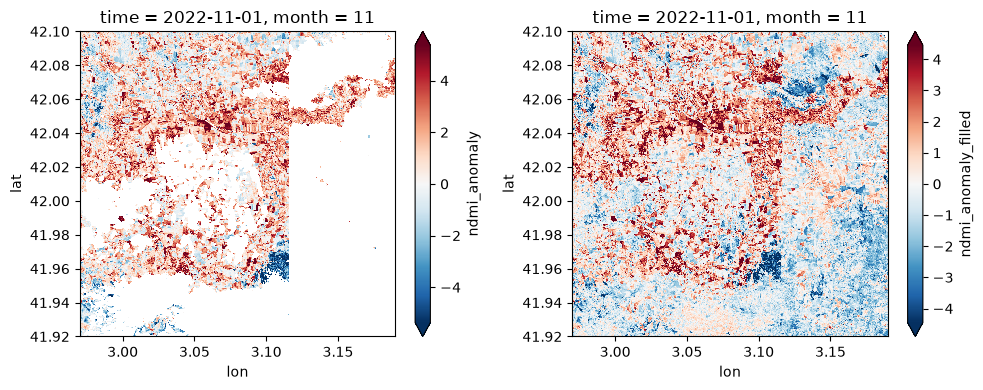

In [10]:
# interpolate missing values by persistence
cube["ndmi_anomaly_filled"] = cube.ndmi_anomaly.ffill("time", limit = 1)
cube["ndvi_anomaly_filled"] = cube.ndvi_anomaly.ffill("time", limit = 1)

fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cube.ndmi_anomaly.sel(time = cube.time[idx]).plot(ax = axes[0], robust = True)
cube.ndmi_anomaly_filled.sel(time = cube.time[idx]).plot(ax = axes[1], robust = True)
plt.tight_layout()

directly filling with past info is clearly misleading when the season changes as we see there, some points are dryer than normal while some others are wetter we'll thus pass valid_mask to the model, so that it can learn which pixels to trust anyway, only a small proportion of the pixels need filling, so that's probably OK

important to note this in the README, since it can yield bad results
if bad results are obtained, explore better options for this (maybe a NN that learns how to fill the missing data?)

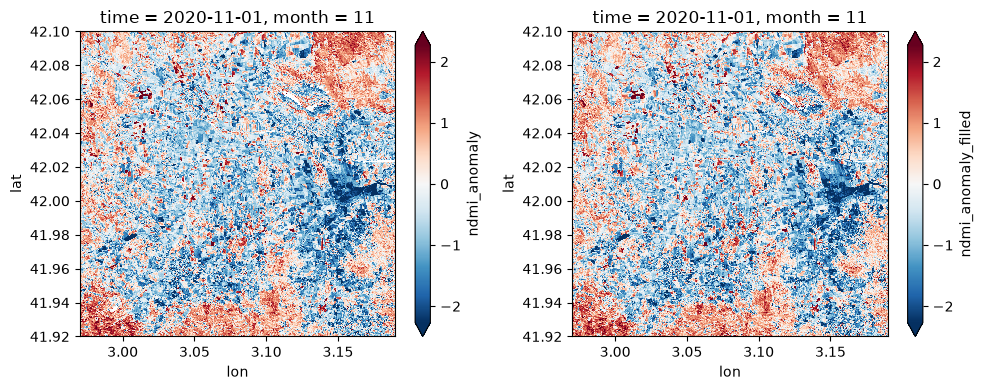

In [11]:
fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cube.ndmi_anomaly.sel(time = cube.time[idx - 24]).plot(ax = axes[0], robust = True)
cube.ndmi_anomaly_filled.sel(time = cube.time[idx - 24]).plot(ax = axes[1], robust = True)
plt.tight_layout()

Encode month in sin and cos, to make the calendar circular (january 1 must be next to december 12), thus to avoid a model to learn a sharp jump

In [12]:

cube["month_sin"] = np.sin(cube.time.dt.month * 2 * np.pi / 12)
cube["month_cos"] = np.cos(cube.time.dt.month * 2 * np.pi / 12)

Compute precipitation anomaly through the Standardised Precipitation Index (SPI)

In [13]:
months_all = [[d.year, d.month] for d in pd.date_range("1991-01", "2025-12", freq="MS")]

# mean daily precipitation
tp = get_era5(coords, months_all, variables = ["total_precipitation"]) 

# monthly total accumulated in mm
tp_mm = fill_sea(tp.tp) * 1000 * tp.time.dt.days_in_month

In [14]:
# SPI on the native grid, then regrid only the study period into the cube
for k in [3, 6, 12]:
    cube["spi" + str(k)] = regrid(spi(tp_mm, k).sel(time = slice("2017-04", "2025-12")), cube, "bilinear")

on the train data, look for irrigated cropfields (kept wet artificially, as compared to rain-fed crops)

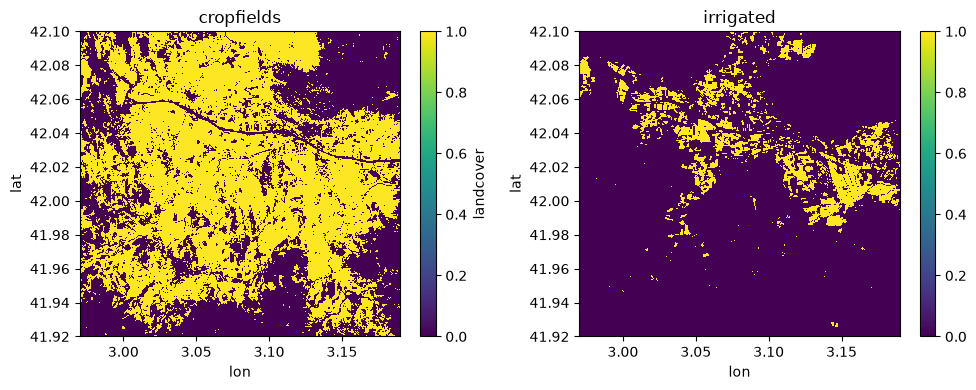

In [15]:
train_ndmi = cube.ndmi_median.sel(time = slice("2017", "2021"))
summer_ndmi = train_ndmi.where(train_ndmi.time.dt.month.isin([7, 8])).mean("time")
cropfields = cube.landcover.isin([30, 40]) # account for grassland and cropland

WET = .25
cube["irrigated"] = (cropfields & (summer_ndmi > WET)).astype("uint8")

fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cropfields.plot(ax = axes[0])
(cropfields & (summer_ndmi > WET)).plot(ax = axes[1])

axes[0].title.set_text('cropfields')
axes[1].title.set_text('irrigated')
plt.tight_layout()

save the cube as a zarr file

In [16]:
# save as zarr
cube.chunk({"time": -1, "lat": 128, "lon": 128}).to_zarr(
    PROCESSED / "cube.zarr", mode = "w")

c:\Users\DavidCirauqui\anaconda3\envs\drought\Lib\site-packages\zarr\api\asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
